# 04 — Modèles de prédiction (train uniquement)

**Question :** à l'atterrissage, quels passagers les équipes doivent-elles aborder en priorité ?

- Ce notebook n'utilise **que le train**. Le test n'est ouvert que dans `05_evaluation_finale`.
- Les méthodes sont comparées par **validation croisée** : le train est coupé en 5 parts, on entraîne sur 4 parts et on évalue sur la 5e, 5 fois de suite.
- Critères : **AUC** (qualité du classement) et **gain en euros** quand on aborde les **10 %** de passagers les plus à risque.
- Formule du gain : passagers abordés × (précision × 100 € − 40 €).

In [1]:
import sys
from pathlib import Path

# Racine du repo = dossier qui contient config.py
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
import modele_utils as mu

pd.set_option("display.float_format", "{:,.3f}".format)
FIGURES = RACINE / "figures"
RESULTATS = RACINE / "resultats"
FIGURES.mkdir(exist_ok=True)
RESULTATS.mkdir(exist_ok=True)
print("Graine :", config.SEED, "| Variables :", config.FEATURES_MODELE)

Graine : 42 | Variables : ['Customer Type', 'Type of Travel', 'Class', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


## 1. Variables connues à l'atterrissage

Le modèle sera appliqué à **tous** les passagers à leur arrivée, y compris ceux qui ne répondent jamais à l'enquête. Il n'utilise donc que les 6 variables de `config.FEATURES_MODELE`. Les 14 notes d'enquête, le genre et l'âge sont exclus.

In [2]:
df, y = mu.charger_train()
print(f"{len(df):,} passagers dans le train, dont {y.mean():.1%} « neutral or dissatisfied »")
df[config.FEATURES_MODELE].head()

103,904 passagers dans le train, dont 56.7% « neutral or dissatisfied »


,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
0,Loyal Customer,Personal Travel,Eco Plus,460,25,18.000
1,disloyal Customer,Business travel,Business,235,1,6.000
2,Loyal Customer,Business travel,Business,1142,0,0.000
3,Loyal Customer,Business travel,Business,562,11,9.000
4,Loyal Customer,Business travel,Business,214,0,0.000


## 2. Règle simple de référence (sans modèle)

Ce que les équipes pourraient faire sans aucun modèle. Si une règle désigne plus de 10 % des passagers, on suppose un tirage au sort parmi eux.

In [3]:
decoupage = mu.plis(y)
COLONNES = ["AUC", "Précision top 10 %", "Gain / 1000 passagers (€)"]

def resume(res):
    out = res[COLONNES].mean()
    out["Gain (écart-type entre plis)"] = res["Gain / 1000 passagers (€)"].std()
    return out

regles = pd.DataFrame({
    nom: resume(mu.cv(y, regle(df).to_numpy(), decoupage)) for nom, regle in mu.REGLES.items()
}).T.sort_values("Gain / 1000 passagers (€)", ascending=False)
regles

,AUC,Précision top 10 %,Gain / 1000 passagers (€),Gain (écart-type entre plis)
Voyage personnel,0.710,0.898,"4,983.464",23.902
Classe Eco / Eco Plus,0.754,0.806,"4,055.955",48.342
Client non fidèle,0.573,0.763,"3,632.490",90.757
Plus gros retard à l'arrivée,0.553,0.642,"2,420.689",80.649


In [4]:
meilleure_regle = regles.index[0]
assert meilleure_regle == mu.REGLE_DE_REFERENCE
print("Règle de référence :", meilleure_regle)

Règle de référence : Voyage personnel


## 3. Deux modèles

- **Régression logistique** : chaque variable ajoute ou retire du risque, et on fait la somme. Les retards et la distance passent par un log.
- **Arbre de décision** (4 niveaux maximum, au moins 50 passagers par feuille) : une suite de questions oui/non, qu'on peut dessiner.

In [5]:
scores = {f"Règle : {meilleure_regle}": mu.REGLES[meilleure_regle](df).to_numpy()}
for nom, fabrique in mu.MODELES.items():
    scores[nom] = mu.scores_hors_pli(df, y, fabrique, decoupage)

## 4. Tableau comparatif (validation croisée, moyenne sur 5 plis)

In [6]:
comparaison = pd.DataFrame({nom: resume(mu.cv(y, s, decoupage)) for nom, s in scores.items()}).T
comparaison.loc["Modèle parfait (borne)"] = [np.nan, 1.0, mu.gain_parfait_par_1000(y), np.nan]
comparaison["Gain vs règle simple (€ / 1000)"] = (
    comparaison["Gain / 1000 passagers (€)"] - comparaison["Gain / 1000 passagers (€)"].iloc[0])
comparaison.to_csv(RESULTATS / "04_comparaison_cv.csv")
comparaison

,AUC,Précision top 10 %,Gain / 1000 passagers (€),Gain (écart-type entre plis),Gain vs règle simple (€ / 1000)
Règle : Voyage personnel,0.710,0.898,"4,983.464",23.902,0.000
Régression logistique,0.846,0.953,"5,525.427",32.562,541.963
Arbre de décision,0.848,0.957,"5,574.604",22.256,591.140
Modèle parfait (borne),NaN,1.000,"6,000.000",NaN,"1,016.536"


## 5. Gain selon le nombre de passagers abordés

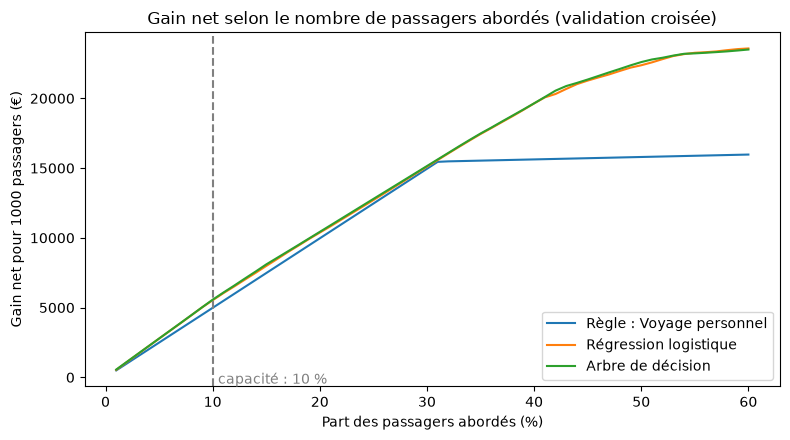

In [7]:
parts = np.linspace(0.01, 0.6, 60)
fig, ax = plt.subplots(figsize=(8, 4.5))
for nom, s in scores.items():
    ax.plot(parts * 100, [mu.evaluer(y, s, p)["Gain / 1000 passagers (€)"] for p in parts], label=nom)
ax.axvline(config.CAPACITE * 100, color="grey", ls="--")
ax.text(config.CAPACITE * 100 + 0.5, ax.get_ylim()[0] + 200, "capacité : 10 %", color="grey")
ax.set_xlabel("Part des passagers abordés (%)")
ax.set_ylabel("Gain net pour 1000 passagers (€)")
ax.set_title("Gain net selon le nombre de passagers abordés (validation croisée)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "04_courbe_gain.png", dpi=150)

Le gain continue de monter au-delà de 10 % : c'est la **capacité des équipes** qui limite le nombre d'approches, pas leur rentabilité.

## 6. Ce que fait l'arbre de décision

L'arbre est entraîné sur tout le train pour pouvoir être lu. Chaque case indique la part de passagers mécontents dans le groupe.

|--- Class_Business <= 0.50
|   |--- Type of Travel_Business travel <= 0.50
|   |   |--- Arrival Delay in Minutes <= 5.50
|   |   |   |--- Flight Distance <= 744.50
|   |   |   |   |--- class: 1
|   |   |   |--- Flight Distance >  744.50
|   |   |   |   |--- class: 1
|   |   |--- Arrival Delay in Minutes >  5.50
|   |   |   |--- Class_Eco Plus <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Class_Eco Plus >  0.50
|   |   |   |   |--- class: 1
|   |--- Type of Travel_Business travel >  0.50
|   |   |--- Customer Type_Loyal Customer <= 0.50
|   |   |   |--- Arrival Delay in Minutes <= 4.50
|   |   |   |   |--- class: 1
|   |   |   |--- Arrival Delay in Minutes >  4.50
|   |   |   |   |--- class: 1
|   |   |--- Customer Type_Loyal Customer >  0.50
|   |   |   |--- Arrival Delay in Minutes <= 5.50
|   |   |   |   |--- class: 0
|   |   |   |--- Arrival Delay in Minutes >  5.50
|   |   |   |   |--- class: 1
|--- Class_Business >  0.50
|   |--- Customer Type_Loyal Customer <= 0.50
|   

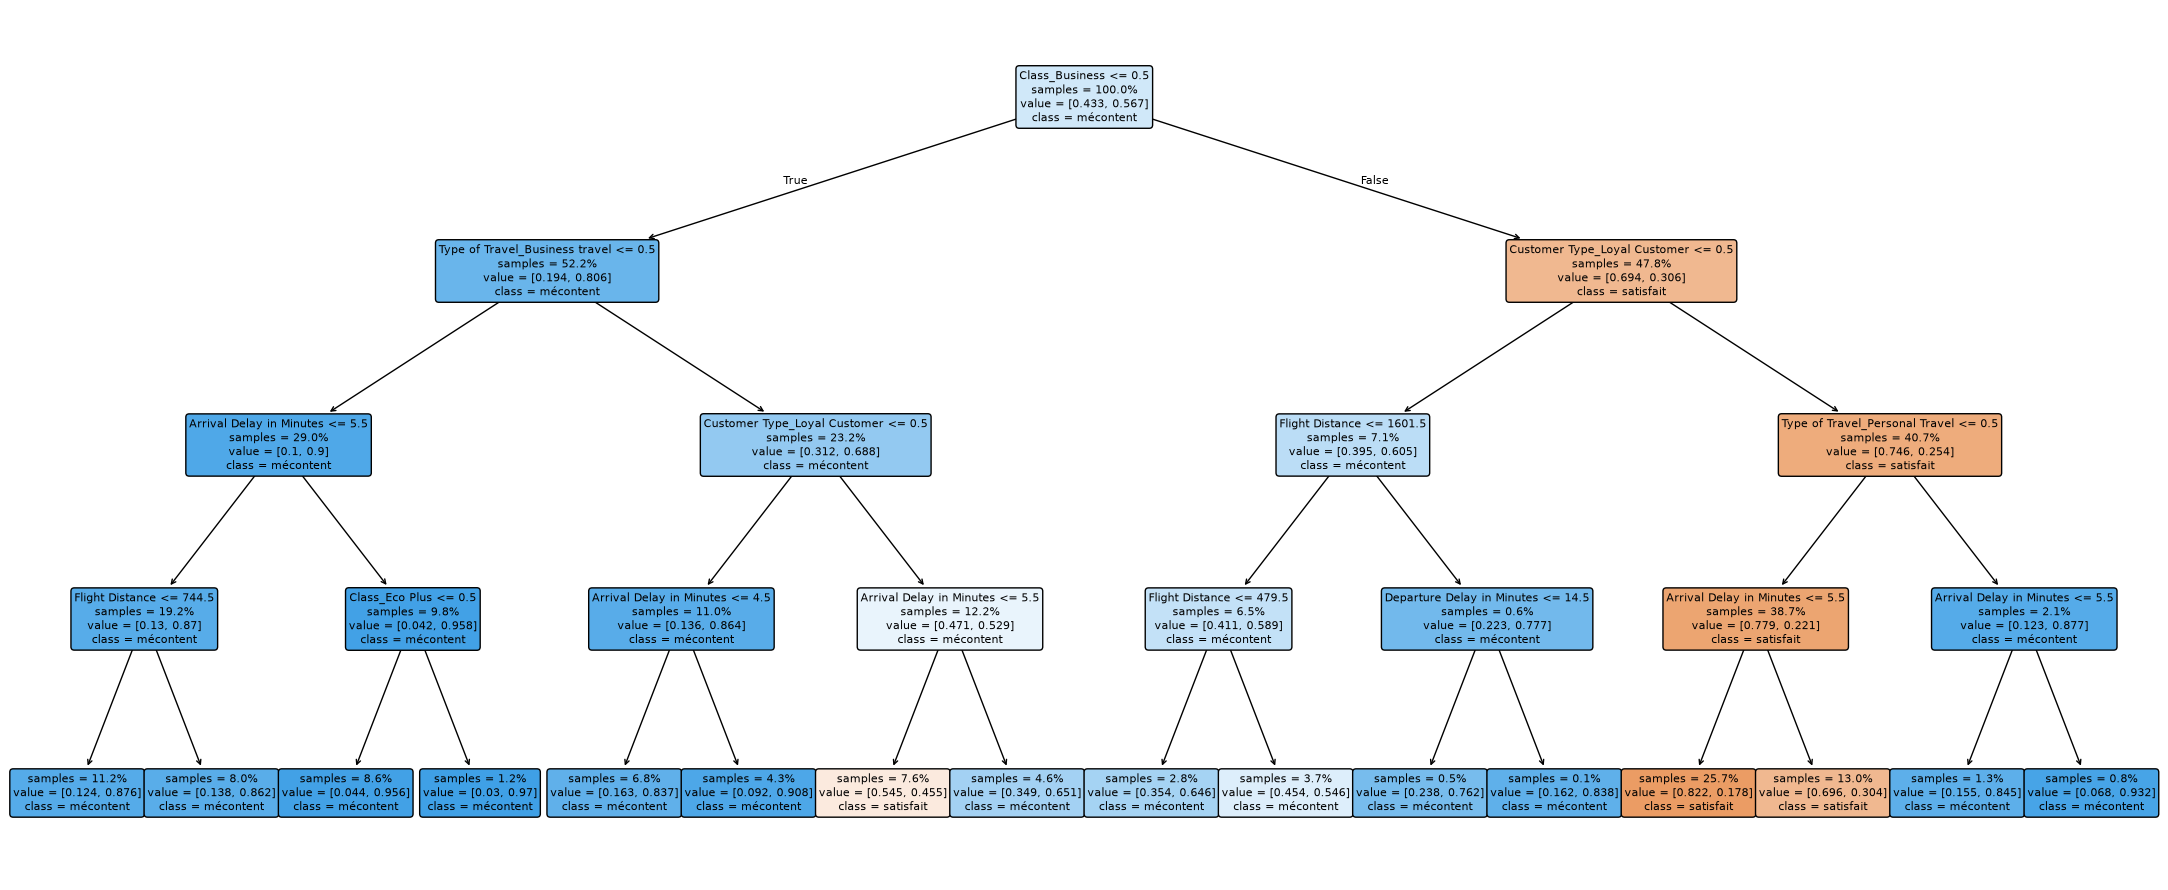

In [8]:
from sklearn.tree import plot_tree, export_text

arbre = mu.arbre_decision().fit(df[config.FEATURES_MODELE], y)
noms = list(arbre.named_steps["prep"].get_feature_names_out())

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arbre.named_steps["clf"], feature_names=noms, class_names=["satisfait", "mécontent"],
          filled=True, proportion=True, impurity=False, rounded=True, fontsize=8, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES / "04_arbre_decision.png", dpi=150)
print(export_text(arbre.named_steps["clf"], feature_names=noms, show_weights=False))

In [9]:
importances = pd.Series(arbre.named_steps["clf"].feature_importances_, index=noms)
importances[importances > 0].sort_values(ascending=False).round(3)

Class_Business                   0.663
Customer Type_Loyal Customer     0.148
Type of Travel_Personal Travel   0.090
Type of Travel_Business travel   0.061
Arrival Delay in Minutes         0.033
Flight Distance                  0.004
Departure Delay in Minutes       0.000
Class_Eco Plus                   0.000
dtype: float64

## 7. Contrôles complémentaires (train uniquement, validation croisée)

Trois questions qu'on nous posera, chiffrées avec les mêmes 5 plis :
- **a) Mineurs.** L'âge n'est pas dans le modèle, mais les mineurs sont-ils sur-représentés parmi les passagers signalés ? Que coûte la règle « aucun mineur signalé » (on les retire de la liste et on prend les adultes suivants) ?
- **b) Âge.** Que gagnerait-on à ajouter l'âge au modèle ?
- **c) Motif du voyage.** Que perd-on si la compagnie ne connaît pas ce motif de façon fiable à l'atterrissage ?

In [10]:
# a) Mineurs parmi les passagers signalés
score_arbre = scores["Arbre de décision"]
mineur = (df["Age"] < 18).to_numpy()
poids = mu.selection_top(score_arbre)
part_mineurs_signales = (poids * mineur).sum() / poids.sum()
print(f"Mineurs : {mineur.mean():.1%} des passagers, {part_mineurs_signales:.1%} des passagers signalés")

# Les mineurs signalés sont-ils aussi souvent vraiment mécontents que les adultes ?
for nom, groupe in [("mineurs", mineur), ("adultes", ~mineur)]:
    print(f"Précision parmi les {nom} signalés : {(poids * groupe * y).sum() / (poids * groupe).sum():.1%}")
print(f"Mineurs en voyage personnel (donc le plus souvent en famille) : "
      f"{(df.loc[mineur, 'Type of Travel'] == 'Personal Travel').mean():.0%}")

# Comparaison : garder les mineurs (choix retenu) ou les retirer de la liste
avec_mineurs = mu.evaluer(y, score_arbre)
sans_mineurs = mu.evaluer(y, np.where(mineur, -1, score_arbre))
print(f"\nAvec les mineurs (retenu) : précision {avec_mineurs['Précision top 10 %']:.1%}, "
      f"gain {avec_mineurs['Gain / 1000 passagers (€)']:,.0f} € / 1000")
print(f"Sans mineur signalé       : précision {sans_mineurs['Précision top 10 %']:.1%}, "
      f"gain {sans_mineurs['Gain / 1000 passagers (€)']:,.0f} € / 1000 "
      f"({sans_mineurs['Gain / 1000 passagers (€)'] - avec_mineurs['Gain / 1000 passagers (€)']:+,.0f} €)")

Mineurs : 7.6% des passagers, 18.0% des passagers signalés
Précision parmi les mineurs signalés : 95.3%
Précision parmi les adultes signalés : 95.7%
Mineurs en voyage personnel (donc le plus souvent en famille) : 72%

Avec les mineurs (retenu) : précision 95.7%, gain 5,567 € / 1000
Sans mineur signalé       : précision 94.7%, gain 5,466 € / 1000 (-101 €)


**Hypothèse « famille » (non mesurable dans nos données).** Un mineur mécontent voyage presque toujours avec sa famille, qui décidera ensemble de revoler ou non avec la compagnie. Aborder la famille d'un enfant mécontent peut donc sauver **plusieurs billets** et non un seul. Les données ne disent pas qui voyage avec qui : on ne peut pas le prouver, seulement le chiffrer. On fait varier le nombre de billets sauvés par mineur mécontent abordé (1 = hypothèse de base de la direction), le coût de l'approche restant de 40 €.

In [11]:
def gain_famille(billets):
    valeur = np.where(mineur, billets, 1) * config.GAIN_VRAI_INSATISFAIT
    gain = (poids * (y * valeur - config.COUT_APPROCHE)).sum()
    return gain / len(y) * 1000

famille = pd.DataFrame({
    "Billets sauvés par mineur mécontent abordé": [1, 2, 3, 4],
    "Gain / 1000 passagers (€)": [gain_famille(k) for k in [1, 2, 3, 4]],
}).set_index("Billets sauvés par mineur mécontent abordé")
famille["Écart vs sans mineurs (€ / 1000)"] = famille["Gain / 1000 passagers (€)"] - sans_mineurs["Gain / 1000 passagers (€)"]
famille.to_csv(RESULTATS / "04_mineurs_hypothese_famille.csv")
famille

,Gain / 1000 passagers (€),Écart vs sans mineurs (€ / 1000)
Billets sauvés par mineur mécontent abordé,,
1,"5,566.839",100.515
2,"7,284.909","1,818.586"
3,"9,002.980","3,536.656"
4,"10,721.050","5,254.727"


In [12]:
# b) et c) Variantes de l'arbre (mêmes réglages, autres variables)
variantes = {
    "Arbre retenu (6 variables)": (mu.CATEGORIELLES, mu.NUMERIQUES),
    "Arbre + âge (non retenu)": (mu.CATEGORIELLES, mu.NUMERIQUES + ["Age"]),
    "Arbre sans motif du voyage": (["Customer Type", "Class"], mu.NUMERIQUES),
}
lignes = {}
for nom, (cat, num) in variantes.items():
    s = mu.scores_hors_pli(df, y, lambda: mu.arbre_decision(cat, num), decoupage, cat + num)
    lignes[nom] = resume(mu.cv(y, s, decoupage))
variantes_cv = pd.DataFrame(lignes).T
variantes_cv["Écart vs arbre retenu (€ / 1000)"] = (
    variantes_cv["Gain / 1000 passagers (€)"] - variantes_cv.loc["Arbre retenu (6 variables)", "Gain / 1000 passagers (€)"])
variantes_cv.to_csv(RESULTATS / "04_variantes_cv.csv")
variantes_cv

,AUC,Précision top 10 %,Gain / 1000 passagers (€),Gain (écart-type entre plis),Écart vs arbre retenu (€ / 1000)
Arbre retenu (6 variables),0.848,0.957,"5,574.604",22.256,0.000
Arbre + âge (non retenu),0.852,0.958,"5,576.678",22.437,2.074
Arbre sans motif du voyage,0.806,0.882,"4,824.151",71.229,-750.453


In [13]:
# d) Gain de l'arbre si les équipes pouvaient aborder plus de passagers
capacites = pd.DataFrame({
    f"{p:.0%}": mu.evaluer(y, score_arbre, p) for p in [0.10, 0.15, 0.20]
}).T[["Précision top 10 %", "Gain / 1000 passagers (€)"]].rename(columns={"Précision top 10 %": "Précision"})
capacites.index.name = "Capacité"
capacites.to_csv(RESULTATS / "04_gain_selon_capacite.csv")
capacites

,Précision,Gain / 1000 passagers (€)
Capacité,,
10%,0.957,"5,566.839"
15%,0.940,"8,095.776"
20%,0.921,"10,429.705"


**Lecture :**
- Les mineurs signalés sont aussi souvent mécontents que les adultes : les garder dans la liste rapporte plus que les retirer, et bien plus encore si l'approche ramène toute la famille. On les garde, à condition de passer **toujours par l'adulte qui les accompagne** (voir la section Protection des données).
- Ajouter l'âge n'apporte presque rien : il reste exclu.
- Le motif du voyage est la variable la plus forte. Sans lui, le gain baisse nettement : il faut vérifier que la compagnie le connaît de façon fiable (réservation entreprise, programme de fidélité).
- Avec plus de capacité, le gain continue d'augmenter : la limite de 10 % est un choix d'organisation, pas de rentabilité.

## 8. Choix du modèle à déployer

- Les deux modèles battent la règle simple d'environ 550 € pour 1 000 passagers.
- L'écart entre eux est faible (de l'ordre de l'écart-type entre plis).
- On retient l'**arbre de décision** : il est au moins aussi rentable et il se **dessine** pour la direction, qui voit pourquoi un passager est signalé.

Ce choix est figé dans `modele_utils.MODELE_RETENU` avant toute ouverture du test.

In [14]:
assert mu.MODELE_RETENU == "Arbre de décision"
print("Modèle retenu :", mu.MODELE_RETENU)

Modèle retenu : Arbre de décision
